In [95]:
import os
import numpy as np
import matplotlib.pyplot as plt
import json

In [96]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Build Data

In [97]:
data = {'infinite welfare': {}, 'finite welfare': {}, 'RHG': {}}

In [98]:
# Infinite Horizon Welfare
directory = 'run_data/two_wells_analysis/infinite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        #print(param_data['controller']['time_horizon'])
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    data['infinite welfare'][well_distance] = result_data['inputs']

In [99]:
# Finite Horizon Welfare
directory = 'run_data/two_wells_analysis/finite_welfare'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['finite welfare'].keys():
        data['finite welfare'][well_distance] = {}
    data['finite welfare'][well_distance][horizon] = result_data['inputs']

In [100]:
# RHG
directory = 'run_data/two_wells_analysis/RHG'
for run in os.listdir(directory):
    with open(os.path.join(directory, run, 'two_wells_analysis_parameters_changed.json')) as f:
        param_data = json.load(f)
        well_distance = np.linalg.norm(np.array(param_data['wells']['pos']).T@np.array([[1,-1]]).T)
        horizon = param_data['controller']['time_horizon']
    result_data = np.load(os.path.join(directory, run, 'result_data.npz'))
    # print(result_data.files)
    if not well_distance in data['RHG'].keys():
        data['RHG'][well_distance] = {}
    data['RHG'][well_distance][horizon] = result_data['inputs']

# Display data

In [101]:
# Order keys/axis
distances = np.sort(list(data['finite welfare'].keys()))
horizons = np.sort(list(data['finite welfare'][distances[0]].keys()))

In [102]:
# Welfare input divergence
finite_infinite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances = np.linalg.norm(
            data['infinite welfare'][distance] - data['finite welfare'][distance][horizon],
            axis=0)
        input_divergences = input_distances / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        finite_infinite_divergence[d][h] = input_divergences.sum()/input_divergences.shape[0]

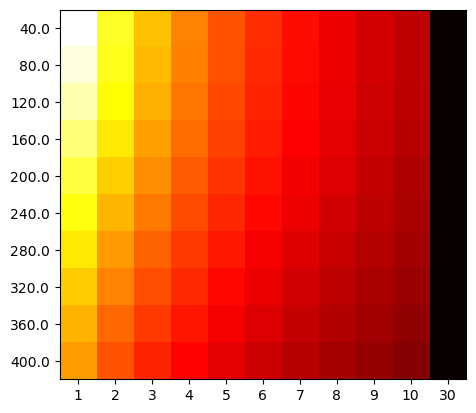

In [103]:
fig, ax = plt.subplots(1,1)
ax.imshow(finite_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

In [104]:
finite_infinite_divergence[0][0]*100

np.float64(0.721583205764773)

In [105]:
# Game/welfare input divergence
RHG_infinite_divergence = np.zeros((len(distances), len(horizons)))
RHG_finite_divergence = np.zeros((len(distances), len(horizons)))
for d, distance in enumerate(distances):
    for h, horizon in enumerate(horizons):
        input_distances_i = np.linalg.norm(
            data['infinite welfare'][distance] - data['RHG'][distance][horizon],
            axis=0)
        input_distances_f = np.linalg.norm(
            data['finite welfare'][distance][horizon] - data['RHG'][distance][horizon],
            axis=0)
        input_divergences_i = input_distances_i / np.linalg.norm(
            data['infinite welfare'][distance], axis=0)
        input_divergences_f = input_distances_f/ np.linalg.norm(
            data['finite welfare'][distance][horizon], axis=0)
        RHG_infinite_divergence[d][h] = input_divergences_i.sum()/input_divergences_i.shape[0]
        RHG_finite_divergence[d][h] = input_divergences_f.sum()/input_divergences_f.shape[0]

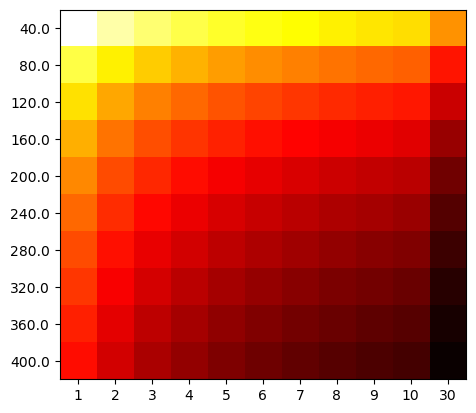

In [106]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_infinite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

In [112]:
RHG_infinite_divergence[0][0]*100, RHG_infinite_divergence[-1][-1]*100

(np.float64(0.9688086149467177), np.float64(0.09418218254953342))

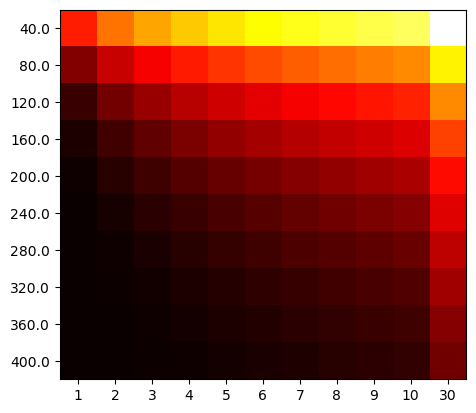

In [108]:
fig, ax = plt.subplots(1,1)
ax.imshow(RHG_finite_divergence, cmap='hot', interpolation='nearest')
ax.set_yticks(np.arange(len(distances)), distances)
ax.set_xticks(np.arange(len(horizons)), horizons)
plt.show()

In [111]:
RHG_finite_divergence.max()*100, RHG_finite_divergence.min()*100

(np.float64(0.6034687381394516), np.float64(2.802389591835921e-06))

In [110]:
RHG_infinite_divergence[0][10]

np.float64(0.006034687381394515)